# Dual-Stream Progressive Hazard Network (DSPHN)
## Merging DAHD + PHRN into One Novel Architecture

### Architecture
```
Shared Encoder
      │
      ├── Appearance Decoder (standard conv)
      ├── Context Decoder (dilated conv)
      │         │
      │   Severity Fusion Gate → Fused Features f4
      │         │
      ├── Stage 1 Head → Binary Safe/Unsafe Map
      │         │
      └── Stage 2 Head ← [f4 ; Stage1_map]
                │
         4-class Hazard Segmentation
```

### Why This is Novel
- DAHD dual decoders come from multi-modal fusion literature
- PHRN hierarchical inference comes from cascade detection literature
- **Nobody has combined appearance-context disentanglement with hierarchical safety-aware inference for RGB segmentation**

### Dataset
ADE20K (3000 images) + Manual annotations (100 images) + COCO knife/scissors (300 images)


## DSPHN: Dual-Stream Progressive Hazard Network
### AIN3002 Final Project, 2026 | Mehreen Faisal
### Department of Artificial Intelligence Engineering

---

## Architecture Overview

**DSPHN integrates two paradigms:**

1. **DAHD dual-stream decoding:**
   - Appearance Decoder (standard convolutions) — learns WHAT hazards look like
   - Context Decoder (dilated convolutions, d={4,3,2,2}) learns WHERE hazards occur
   - Severity Fusion Gates blends appearance and context guided by injury risk scores

2. **PHRN hierarchical inference:**
   - Stage 1 Head → binary safe/unsafe map from fused features
   - Stage 2 Head → 4-class segmentation conditioned on Stage 1 map

**4 Classes:** Background | Safe Floor | Obstacle | Sharp Objects

**Dataset:** ADE20K (3,000) + Manual annotations (100, Make Sense AI) + COCO knife/scissors (186)

**Final Results:** mIoU = 0.4198 | Pixel Accuracy = 0.8332 | Best Val mIoU = 0.4847

In [ ]:

# DUAL-STREAM PROGRESSIVE HAZARD NETWORK (DSPHN)
# Combines DAHD + PHRN into one unified novel architecture
#
# DAHD contribution:
#   Appearance Decoder (standard conv) — learns WHAT hazards look like
#   Context Decoder (dilated conv)     — learns WHERE hazards occur
#   Severity Fusion Gate               — severity-guided feature fusion
#
# PHRN contribution:
#   Stage 1 Head → binary safe/unsafe map from fused features
#   Stage 2 Head → 4-class segmentation conditioned on Stage 1 map
#
# Neither component alone is the novelty.
# The integration of appearance-context disentanglement with
# hierarchical safety-aware inference is the contribution.



## Cell 1: Libraries and Setup
Import all required libraries including PyTorch, torchvision, PIL, numpy, and sklearn. Mount Google Drive for saving model checkpoints.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, random, json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image, ImageDraw
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF
from sklearn.model_selection import train_test_split

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

Mounted at /content/drive
Device: cuda
GPU: Tesla T4


In [ ]:
from pathlib import Path
print("merged_annotations.json:", Path("/content/merged_annotations.json").exists())
print("Manual dataset 1.zip:", Path("/content/Manual dataset 1.zip").exists())
print("Drive mounted:", Path("/content/drive/MyDrive").exists())

merged_annotations.json: True
Manual dataset 1.zip: True
Drive mounted: True


## Cell 2: Constants and Configuration
Define all hyperparameters and class definitions. NUM_CLASSES=4 for our hazard taxonomy. Output directory set to Google Drive to prevent data loss on Colab disconnect.

In [ ]:
NUM_CLASSES  = 4
IMAGE_SIZE   = 256
BATCH_SIZE   = 8
NUM_EPOCHS   = 15
OUTPUT_DIR   = Path('/content/drive/MyDrive/PHRN_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES  = ['Background', 'Safe Floor', 'Obstacle', 'Sharp Objects']
CLASS_COLORS = {0:[50,50,50], 1:[0,200,0], 2:[255,140,0], 3:[255,0,0]}
FLOOR_CLASSES     = [3, 6, 9, 11]
FURNITURE_CLASSES = [5, 10, 14, 18, 22, 24, 30]
CLUTTER_CLASSES   = [33, 34, 36, 39, 41, 43, 44, 62, 71, 88, 125]
SHARP_CLASSES     = [96, 97]

print('Constants defined. Classes:', CLASS_NAMES)


Constants defined. Classes: ['Background', 'Safe Floor', 'Obstacle', 'Sharp Objects']


## Cell 3: Dataset Paths and 70/15/15 Split
Load ADE20K image and annotation paths. Apply a strict 70/15/15 train/validation/test split with fixed seed=42 for reproducibility. Test set is never used during training or hyperparameter selection.

In [ ]:
DATASET_ROOT = Path('/content/drive/MyDrive/ADEChallengeData2016')

train_img_dir  = DATASET_ROOT / 'images'      / 'training'
train_mask_dir = DATASET_ROOT / 'annotations' / 'training'
val_img_dir    = DATASET_ROOT / 'images'      / 'validation'
val_mask_dir   = DATASET_ROOT / 'annotations' / 'validation'

all_images = (sorted(list(train_img_dir.glob('*.jpg'))) +
              sorted(list(val_img_dir.glob('*.jpg'))))
all_masks  = (sorted(list(train_mask_dir.glob('*.png'))) +
              sorted(list(val_mask_dir.glob('*.png'))))

paired = list(zip(all_images, all_masks))[:3000]

train_pairs, temp  = train_test_split(paired, test_size=0.30, random_state=42)
val_pairs,   test_pairs = train_test_split(temp,  test_size=0.50, random_state=42)

train_images, train_masks = zip(*train_pairs)
val_images,   val_masks   = zip(*val_pairs)
test_images,  test_masks  = zip(*test_pairs)

train_images = list(train_images); train_masks = list(train_masks)
val_images   = list(val_images);   val_masks   = list(val_masks)
test_images  = list(test_images);  test_masks  = list(test_masks)

print(f'Train: {len(train_images)} | Val: {len(val_images)} | Test: {len(test_images)}')

Train: 2100 | Val: 450 | Test: 450


## Cell 4: File Setup
Copy merged_annotations.json from Drive and unzip manual dataset images. These 100 manually annotated images (Make Sense AI) are our dataset contribution.

In [ ]:
import subprocess
from pathlib import Path

# Use merged annotations directly. Do not copy/rename it.
JSON_PATH = Path("/content/merged_annotations.json")

# Unzip manual dataset images
ZIP_PATH = "/content/Manual dataset 1.zip"
EXTRACT_DIR = Path("/content/Manual dataset")

if not EXTRACT_DIR.exists():
    subprocess.run(
        ["unzip", "-q", ZIP_PATH, "-d", str(EXTRACT_DIR)],
        capture_output=True
    )
    print("Images unzipped.")
else:
    print("Images already extracted.")

# Verify JSON exists
if JSON_PATH.exists():
    print("Merged JSON found:", JSON_PATH)
else:
    print("Merged JSON NOT found. Upload merged_annotations.json first.")

# Verify extracted image folders
print("\nExtracted folders:")
for p in EXTRACT_DIR.rglob("*"):
    if p.is_dir():
        print(p)

# Count image files
image_exts = [".jpg", ".jpeg", ".png", ".webp", ".avif"]
manual_images = [
    p for p in EXTRACT_DIR.rglob("*")
    if p.suffix.lower() in image_exts
]

print("\nManual images found:", len(manual_images))

Images unzipped.
Merged JSON found: /content/merged_annotations.json

Extracted folders:
/content/Manual dataset/Manual dataset 1
/content/Manual dataset/Manual dataset 1/clutter
/content/Manual dataset/Manual dataset 1/Wet Floor
/content/Manual dataset/Manual dataset 1/Sharp objcets
/content/Manual dataset/Manual dataset 1/Old Images
/content/Manual dataset/Manual dataset 1/Old Images/Old dataset

Manual images found: 251


## Cell 5: Mask Generation from Manual Annotations
Convert polygon annotations from merged_annotations.json into pixel-level PNG masks. Uses exact label string matching to map annotation labels to 4 hazard classes. Safe Floor=1, Obstacle=2, Sharp Objects=3.

In [ ]:
import json as json_lib
from pathlib import Path
from PIL import Image, ImageDraw

JSON_PATH = Path("/content/merged_annotations.json")
MASK_DIR  = Path("/content/merged_masks")
MASK_DIR.mkdir(parents=True, exist_ok=True)

LABEL_MAP = {
    'background':         0,
    'dry floor':          1, 'wet floor': 1, 'safe floor': 1, 'floor': 1,
    'furniture':          2, 'clutter': 2, 'clutter/ obstacles': 2, 'obstacle': 2,
    'sharp objects':      3, 'sharp object': 3, 'knife': 3, 'scissors': 3,
}
NAME_MAP = {0:'Background', 1:'Safe Floor', 2:'Obstacle', 3:'Sharp Objects'}

if JSON_PATH.exists():
    with open(JSON_PATH, "r") as f:
        data = json_lib.load(f)
    created = 0
    counts  = {n:0 for n in NAME_MAP.values()}
    for key, img_data in data.items():
        if not isinstance(img_data, dict): continue
        filename = img_data.get("filename", key)
        regions  = img_data.get("regions", {})
        if isinstance(regions, dict): regions = list(regions.values())
        mask = Image.new("L", (256,256), 0)
        draw = ImageDraw.Draw(mask)
        has_label = False
        for region in regions:
            if not isinstance(region, dict): continue
            ra    = region.get("region_attributes", {})
            sa    = region.get("shape_attributes", {})
            label = ra.get("label", ra.get("Label","")).strip().lower()
            pv    = LABEL_MAP.get(label, -1)
            if pv < 0: continue
            all_x = sa.get("all_points_x", [])
            all_y = sa.get("all_points_y", [])
            if len(all_x) > 2:
                draw.polygon(list(zip(all_x, all_y)), fill=pv)
                has_label = True
                counts[NAME_MAP[pv]] += 1
        if has_label:
            mask.save(MASK_DIR / f"{Path(filename).stem}.png")
            created += 1
    print(f"Masks created: {created}")
    for n,c in counts.items():
        print(f"  {n:<16}: {c}  {'✅' if c>0 else '⚠️'}")
else:
    print("❌ merged_annotations.json not found")


Masks created: 199
  Background      : 17  ✅
  Safe Floor      : 107  ✅
  Obstacle        : 222  ✅
  Sharp Objects   : 186  ✅


## Cell 6: Mask Remapping and Dataset Class
Remap ADE20K 150-class annotations to our 4-class hazard taxonomy. Manual annotation masks override ADE20K labels where available (higher quality). HazardDataset handles both ADE20K and COCO images correctly.

In [ ]:
def remap_mask(ade_mask, hazard_mask=None):
    ade      = np.array(ade_mask)
    remapped = np.zeros_like(ade, dtype=np.uint8)
    for cls in FLOOR_CLASSES:                       remapped[ade==cls] = 1
    for cls in FURNITURE_CLASSES + CLUTTER_CLASSES: remapped[ade==cls] = 2
    for cls in SHARP_CLASSES:                       remapped[ade==cls] = 3
    if hazard_mask is not None:
        hm = np.array(hazard_mask)
        remapped[hm==1] = 1
        remapped[hm==2] = 2
        remapped[hm==3] = 3
    return remapped

image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])

COCO_IMG_DIR = Path('/content/coco_sharp/images')

class HazardDataset(Dataset):
    def __init__(self, image_paths, mask_paths,
                 hazard_annotation_dir="/content/merged_masks", augment=False):
        self.image_paths = [Path(p) for p in image_paths]
        self.mask_paths  = [Path(p) for p in mask_paths]
        self.hazard_dir  = Path(hazard_annotation_dir)
        self.augment     = augment

    def __len__(self): return len(self.image_paths)

    def _is_coco(self, p): return Path(p).parent == COCO_IMG_DIR

    def _load_hazard_mask(self, p):
        mp = self.hazard_dir / (Path(p).stem + '.png')
        return Image.open(mp).convert('L') if mp.exists() else None

    def __getitem__(self, idx):
        image    = Image.open(self.image_paths[idx]).convert('RGB')
        ade_mask = Image.open(self.mask_paths[idx])
        if self.augment and random.random() > 0.5:
            image    = TF.hflip(image)
            ade_mask = TF.hflip(ade_mask)
        ade_mask = ade_mask.resize((IMAGE_SIZE, IMAGE_SIZE), Image.NEAREST)
        if self._is_coco(self.image_paths[idx]):
            final_mask = np.array(ade_mask, dtype=np.uint8)
        else:
            haz = self._load_hazard_mask(self.image_paths[idx])
            if haz: haz = haz.resize((IMAGE_SIZE,IMAGE_SIZE), Image.NEAREST)
            final_mask = remap_mask(ade_mask, haz)
        return image_transform(image), torch.tensor(final_mask, dtype=torch.long)

train_dataset = HazardDataset(train_images, train_masks, augment=True)
val_dataset   = HazardDataset(val_images,   val_masks,   augment=False)
test_dataset  = HazardDataset(test_images,  test_masks,  augment=False)
train_loader  = DataLoader(train_dataset, BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader    = DataLoader(val_dataset,   BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader   = DataLoader(test_dataset,  BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print(f'Train:{len(train_loader)} Val:{len(val_loader)} Test:{len(test_loader)} batches')


Train:263 Val:57 Test:57 batches


## Cell 7: COCO Sharp Objects Integration
Download COCO 2017 validation images containing knives (category 49) and scissors (category 87). No floor constraint applied — sharp objects are hazards anywhere in the scene. Adds 186 images to training set for Sharp Objects supervision.

In [ ]:
# COCO Sharp Objects — knife and scissors anywhere in scene
!pip install pycocotools --quiet
from pycocotools.coco import COCO
import requests, subprocess, shutil

COCO_DIR      = Path('/content/coco_sharp')
COCO_IMG_DIR  = COCO_DIR / 'images'
COCO_MASK_DIR = COCO_DIR / 'masks'
COCO_IMG_DIR.mkdir(parents=True, exist_ok=True)
COCO_MASK_DIR.mkdir(parents=True, exist_ok=True)

ANN_PATH = COCO_DIR / 'instances_val2017.json'
if not ANN_PATH.exists():
    print('Downloading COCO annotations (~240MB)...')
    subprocess.run(['wget','-q','-O','/content/coco_ann.zip',
        'http://images.cocodataset.org/annotations/annotations_trainval2017.zip'])
    subprocess.run(['unzip','-q','/content/coco_ann.zip',
        'annotations/instances_val2017.json','-d',str(COCO_DIR)])
    shutil.move(str(COCO_DIR/'annotations/instances_val2017.json'), str(ANN_PATH))
    print('✅ Done.')
else:
    print('✅ Already present.')

coco = COCO(str(ANN_PATH))
SHARP_IDS = coco.getCatIds(catNms=['knife','scissors'])
print('Sharp category IDs:', SHARP_IDS)

img_ids = set()
for cid in SHARP_IDS: img_ids.update(coco.getImgIds(catIds=[cid]))
print(f'Images with knives/scissors: {len(img_ids)}')

downloaded = 0
for img_id in list(img_ids):
    if downloaded >= 300: break
    info = coco.loadImgs(img_id)[0]
    W,H  = info['width'], info['height']
    aids = coco.getAnnIds(imgIds=img_id, catIds=SHARP_IDS)
    anns = coco.loadAnns(aids)
    if not anns: continue
    mask  = np.zeros((H,W), dtype=np.uint8)
    valid = False
    for ann in anns:
        if ann.get('iscrowd',0): continue
        bm = coco.annToMask(ann)
        if bm.sum() >= 200:
            mask[bm.astype(bool)] = 3
            valid = True
    if not valid: continue
    ip = COCO_IMG_DIR / info['file_name']
    if not ip.exists():
        try:
            r = requests.get(info['coco_url'], timeout=15)
            if r.status_code == 200:
                with open(ip,'wb') as f: f.write(r.content)
        except: continue
    if not ip.exists(): continue
    Image.fromarray(mask).resize((256,256),Image.NEAREST).save(
        COCO_MASK_DIR/(ip.stem+'.png'))
    downloaded += 1
    if downloaded % 50 == 0: print(f'  {downloaded} downloaded...')

print(f'✅ COCO sharp object images: {downloaded}')

pairs = [(p, COCO_MASK_DIR/(p.stem+'.png'))
         for p in COCO_IMG_DIR.glob('*.jpg')
         if (COCO_MASK_DIR/(p.stem+'.png')).exists()]
for ip,mp in pairs:
    train_images.append(ip); train_masks.append(mp)

train_dataset = HazardDataset(train_images, train_masks, augment=True)
train_loader  = DataLoader(train_dataset, BATCH_SIZE, shuffle=True,
                           num_workers=2, pin_memory=True)
sharp = sum(1 for _,m in train_dataset if 3 in torch.unique(m))
print(f'✅ Sharp Object training images: {sharp}')
print(f'✅ Train batches: {len(train_loader)}')


✅ Done.
loading annotations into memory...
Done (t=0.53s)
creating index...
index created!
Sharp category IDs: [49, 87]
Images with knives/scissors: 207
  50 downloaded...
  100 downloaded...
  150 downloaded...
✅ COCO sharp object images: 186
✅ Sharp Object training images: 230
✅ Train batches: 286


## Cell 8: DSPHN Architecture
Complete Dual-Stream Progressive Hazard Network implementation.

**DAHD components:**
- AppUpBlock: Appearance Decoder using standard convolutions learns local texture and colour patterns
- CtxUpBlock: Context Decoder using dilated convolutions (d={4,3,2,2})learns spatial relationships
- SeverityFusionGate: Blends appearance and context features using severity-initialised gates

**PHRN components:**
- Stage 1 Head: Produces binary safe/unsafe map from fused features f4
- Stage 2 Head: Receives [f4; Stage1_map] and produces 4 class segmentation

Stage 1 map is a direct structural input to Stage 2, not an auxiliary loss.

In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch,  out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x): return self.conv(x)

class DilatedConv(nn.Module):
    def __init__(self, in_ch, out_ch, dilation=2):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=dilation, dilation=dilation),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=dilation, dilation=dilation),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x): return self.conv(x)

class DownBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(nn.MaxPool2d(2), DoubleConv(in_ch, out_ch))
    def forward(self, x): return self.block(x)

class AppUpBlock(nn.Module):
    """Appearance decoder upsampling block — standard conv."""
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up   = nn.ConvTranspose2d(in_ch, in_ch//2, 2, stride=2)
        self.conv = DoubleConv(in_ch//2 + skip_ch, out_ch)
    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[2:] != skip.shape[2:]:
            x = F.interpolate(x, size=skip.shape[2:], mode='bilinear', align_corners=False)
        return self.conv(torch.cat([x, skip], dim=1))

class CtxUpBlock(nn.Module):
    """Context decoder upsampling block — dilated conv."""
    def __init__(self, in_ch, skip_ch, out_ch, dilation=2):
        super().__init__()
        self.up   = nn.ConvTranspose2d(in_ch, in_ch//2, 2, stride=2)
        self.conv = DilatedConv(in_ch//2 + skip_ch, out_ch, dilation)
    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[2:] != skip.shape[2:]:
            x = F.interpolate(x, size=skip.shape[2:], mode='bilinear', align_corners=False)
        return self.conv(torch.cat([x, skip], dim=1))

class SeverityFusionGate(nn.Module):
    """
    DAHD component: severity-guided fusion of appearance and context.
    Gate initialized from domain hazard severity scores.
    Learns when to trust appearance vs spatial context per pixel.
    """
    def __init__(self, channels, severity_scores=None):
        super().__init__()
        self.fusion = nn.Sequential(
            nn.Conv2d(channels*2, channels, 1, bias=False),
            nn.BatchNorm2d(channels), nn.ReLU(inplace=True),
            nn.Conv2d(channels, 1, 1, bias=False))
        init = severity_scores.clone().float() if severity_scores is not None                else torch.ones(NUM_CLASSES)*0.5
        self.severity_bias = nn.Parameter(init)
        self.severity_proj = nn.Linear(NUM_CLASSES, 1, bias=False)

    def forward(self, f_app, f_ctx):
        alpha = self.fusion(torch.cat([f_app, f_ctx], dim=1))
        sev   = self.severity_proj(self.severity_bias.unsqueeze(0)).view(1,1,1,1)
        alpha = torch.sigmoid(alpha + sev)
        return alpha*f_app + (1-alpha)*f_ctx, alpha

class DualStreamProgressiveHazardNetwork(nn.Module):
    """
    DSPHN: Dual-Stream Progressive Hazard Network

    Combines:
    1. DAHD dual-stream decoders (appearance + context) with
       severity-guided fusion gates
    2. PHRN two-stage hierarchical inference where Stage 1 binary
       map conditions Stage 2 classification

    Forward pass:
      Shared encoder → dual-stream decoders → severity fusion → f4
      f4 → Stage 1 Head → binary safe/unsafe map
      [f4 ; Stage1_map] → Stage 2 Head → 4-class segmentation

    Neither DAHD nor PHRN alone is the contribution.
    The principled integration of appearance-context disentanglement
    with hierarchical safety-aware inference is the novel design.
    """
    def __init__(self, num_classes=4, severity_scores=None):
        super().__init__()
        sev = severity_scores

        # Shared Encoder
        self.enc1 = DoubleConv(3,   64)
        self.enc2 = DownBlock(64,  128)
        self.enc3 = DownBlock(128, 256)
        self.enc4 = DownBlock(256, 512)
        self.bot  = DownBlock(512, 1024)
        self.drop = nn.Dropout2d(0.3)

        # DAHD: Appearance Decoder (standard conv)
        self.app1 = AppUpBlock(1024, 512, 512)
        self.app2 = AppUpBlock(512,  256, 256)
        self.app3 = AppUpBlock(256,  128, 128)
        self.app4 = AppUpBlock(128,   64,  64)

        # DAHD: Context Decoder (dilated conv)
        self.ctx1 = CtxUpBlock(1024, 512, 512, dilation=4)
        self.ctx2 = CtxUpBlock(512,  256, 256, dilation=3)
        self.ctx3 = CtxUpBlock(256,  128, 128, dilation=2)
        self.ctx4 = CtxUpBlock(128,   64,  64, dilation=2)

        # DAHD: Severity Fusion Gates
        self.gate1 = SeverityFusionGate(512, sev)
        self.gate2 = SeverityFusionGate(256, sev)
        self.gate3 = SeverityFusionGate(128, sev)
        self.gate4 = SeverityFusionGate(64,  sev)

        #  PHRN: Stage 1 — Binary Hazard Head
        # Takes fused features f4 → binary safe/unsafe map
        self.stage1_head = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, 1),
            nn.Sigmoid()
        )

        # PHRN: Stage 2 — Fine Classifier
        # Takes [f4 ; Stage1_map] → 4-class segmentation
        # +1 channel for Stage 1 binary map
        self.stage2_head = nn.Sequential(
            nn.Conv2d(64 + 1, 64, 3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64, num_classes, 1)
        )

    def forward(self, x):
        # Shared encoder
        e1 = self.enc1(x); e2 = self.enc2(e1)
        e3 = self.enc3(e2); e4 = self.enc4(e3)
        b  = self.drop(self.bot(e4))

        # Appearance decoder
        a1 = self.app1(b,  e4); a2 = self.app2(a1, e3)
        a3 = self.app3(a2, e2); a4 = self.app4(a3, e1)

        # Context decoder
        c1 = self.ctx1(b,  e4); c2 = self.ctx2(c1, e3)
        c3 = self.ctx3(c2, e2); c4 = self.ctx4(c3, e1)

        # Severity fusion gates
        f1, _ = self.gate1(a1, c1)
        f2, _ = self.gate2(a2, c2)
        f3, _ = self.gate3(a3, c3)
        f4, _ = self.gate4(a4, c4)  # final fused features

        # Stage 1: binary safe/unsafe map from fused features
        stage1_map = self.stage1_head(f4)  # (B, 1, H, W)

        # Stage 2: fine classification conditioned on Stage 1
        # Concatenate Stage 1 map to fused features
        stage2_input = torch.cat([f4, stage1_map], dim=1)  # (B, 65, H, W)
        stage2_seg   = self.stage2_head(stage2_input)       # (B, 4, H, W)

        return stage2_seg, stage1_map


# Instantiate
HAZARD_SEVERITY = torch.tensor([0.0, 0.1, 0.6, 0.9], dtype=torch.float32)
model = DualStreamProgressiveHazardNetwork(
    num_classes=NUM_CLASSES,
    severity_scores=HAZARD_SEVERITY
).to(device)

dummy = torch.randn(2, 3, 256, 256).to(device)
with torch.no_grad():
    seg, s1 = model(dummy)

total = sum(p.numel() for p in model.parameters() if p.requires_grad)
print('✅ DSPHN verified!')
print(f'   Stage 1 (binary map) : {s1.shape}')
print(f'   Stage 2 (4-class seg): {seg.shape}')
print(f'   Parameters           : {total:,}')
print()
print('Components:')
print('  DAHD: Appearance Decoder + Context Decoder + Severity Fusion Gates')
print('  PHRN: Stage 1 binary head + Stage 2 conditioned classification')


✅ DSPHN verified!
   Stage 1 (binary map) : torch.Size([2, 1, 256, 256])
   Stage 2 (4-class seg): torch.Size([2, 4, 256, 256])
   Parameters           : 43,991,461

Components:
  DAHD: Appearance Decoder + Context Decoder + Severity Fusion Gates
  PHRN: Stage 1 binary head + Stage 2 conditioned classification


## Cell 9: Loss Function
Combined loss: L = 0.5 * CE + 0.5 * Dice + 0.4 * BCE_Stage1

- CE: Class-weighted cross-entropy with weights [0.5, 1.5, 2.0, 6.0]
- Dice: Multi-class Dice loss for region overlap optimisation
- BCE_Stage1: Binary cross-entropy ensuring Stage 1 learns accurate hazard maps before Stage 2 depends on them

Sharp Objects receives highest weight (6.0) to compensate for extreme class imbalance.

In [ ]:
class DiceLoss(nn.Module):
    def __init__(self, nc=4, smooth=1e-6):
        super().__init__()
        self.nc=nc; self.smooth=smooth
    def forward(self, logits, targets):
        probs = F.softmax(logits, dim=1)
        toh   = F.one_hot(targets, self.nc).permute(0,3,1,2).float()
        scores = [(2*(probs[:,c]*toh[:,c]).sum()+self.smooth)/
                  (probs[:,c].sum()+toh[:,c].sum()+self.smooth)
                  for c in range(self.nc)]
        return 1 - torch.stack(scores).mean()

CLASS_WEIGHTS = torch.tensor([0.5,1.5,2.0,6.0], dtype=torch.float32)
dice_fn = DiceLoss(NUM_CLASSES)

def dsphn_loss(stage2_logits, stage1_map, targets,
               lce=0.5, ldice=0.5, ls1=0.4):
    """
    DSPHN Combined Loss:
      CE + Dice on Stage 2 (4-class fine segmentation)
      BCE on Stage 1 (binary hazard map supervision)
    Stage 1 loss ensures binary map is accurate before Stage 2 uses it.
    """
    w  = CLASS_WEIGHTS.to(stage2_logits.device)
    ce = F.cross_entropy(stage2_logits, targets, weight=w)
    dl = dice_fn(stage2_logits, targets)
    s1t = (targets > 0).float().unsqueeze(1)
    s1l = F.binary_cross_entropy(stage1_map, s1t)
    return lce*ce + ldice*dl + ls1*s1l, ce.item(), dl.item(), s1l.item()

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=2)
print('✅ DSPHN loss ready.')
print('   Stage 2: CE + Dice | Stage 1: Binary BCE')
print('   Class weights:', CLASS_WEIGHTS.numpy())


✅ DSPHN loss ready.
   Stage 2: CE + Dice | Stage 1: Binary BCE
   Class weights: [0.5 1.5 2.  6. ]


## Cell 10: Evaluation Metrics
Define pixel accuracy, mean IoU, and mean Dice score functions. Mean IoU is the primary evaluation metric as it penalises both false positives and false negatives equally.

In [ ]:
def pixel_accuracy(pred, target):
    return (pred == target).float().mean().item()

def mean_iou(pred, target, nc=NUM_CLASSES):
    iou = []
    for c in range(nc):
        p = (pred==c); t = (target==c)
        inter = (p&t).sum().float()
        union = (p|t).sum().float()
        if union > 0: iou.append((inter/(union+1e-6)).item())
    return np.mean(iou) if iou else 0.0

def mean_dice(pred, target, nc=NUM_CLASSES):
    dice = []
    for c in range(nc):
        p = (pred==c).float(); t = (target==c).float()
        inter = (p*t).sum(); denom = p.sum()+t.sum()
        if denom > 0: dice.append((2*inter/(denom+1e-6)).item())
    return np.mean(dice) if dice else 0.0

print('Metrics defined.')

Metrics defined.


## Cell 11: Training Loop
Train DSPHN for 15 epochs with Adam optimizer (lr=1e-4) and ReduceLROnPlateau scheduler. Best model saved to Drive after every improvement in validation mIoU. Training history saved after every epoch to prevent data loss.

In [ ]:
history = {'train_loss':[],'val_loss':[],'val_acc':[],'val_miou':[],'val_dice':[]}
best_miou = 0.0

for epoch in range(NUM_EPOCHS):
    model.train(); tl = 0.0
    for bi,(imgs,masks) in enumerate(train_loader):
        imgs,masks = imgs.to(device),masks.to(device)
        optimizer.zero_grad()
        seg,s1 = model(imgs)
        loss,ce_v,dice_v,s1_v = dsphn_loss(seg,s1,masks)
        loss.backward(); optimizer.step()
        tl += loss.item()
        if (bi+1)%50==0:
            print(f'Ep{epoch+1:02d}/{NUM_EPOCHS} B{bi+1:03d} '
                  f'L={loss.item():.4f} [CE={ce_v:.3f} D={dice_v:.3f} S1={s1_v:.3f}]')

    avg_tl = tl/len(train_loader)
    model.eval(); vl,accs,mious,dices = 0.0,[],[],[]
    with torch.no_grad():
        for imgs,masks in val_loader:
            imgs,masks = imgs.to(device),masks.to(device)
            seg,s1 = model(imgs)
            loss,*_ = dsphn_loss(seg,s1,masks)
            vl += loss.item()
            preds = torch.argmax(seg,1)
            accs.append(pixel_accuracy(preds,masks))
            mious.append(mean_iou(preds.cpu(),masks.cpu()))
            dices.append(mean_dice(preds.cpu(),masks.cpu()))

    avg_vl=vl/len(val_loader); avg_acc=np.mean(accs)
    avg_miou=np.mean(mious);   avg_dice=np.mean(dices)
    scheduler.step(avg_vl)
    history['train_loss'].append(avg_tl); history['val_loss'].append(avg_vl)
    history['val_acc'].append(avg_acc);   history['val_miou'].append(avg_miou)
    history['val_dice'].append(avg_dice)

    with open('/content/drive/MyDrive/DSPHN_history.json','w') as f:
        json.dump(history,f)

    print(f'\n>>> Ep{epoch+1:02d}/{NUM_EPOCHS} | TL={avg_tl:.4f} VL={avg_vl:.4f} | '
          f'Acc={avg_acc:.4f} mIoU={avg_miou:.4f} Dice={avg_dice:.4f}')

    if avg_miou > best_miou:
        best_miou = avg_miou
        torch.save(model.state_dict(),'/content/drive/MyDrive/best_DSPHN_model.pth')
        print(f'  ✓ Best saved (mIoU={best_miou:.4f})')

torch.save(model.state_dict(),'/content/drive/MyDrive/final_DSPHN_model.pth')
with open('/content/drive/MyDrive/DSPHN_history.json','w') as f: json.dump(history,f)
print(f'\n✅ Training complete. Best mIoU: {best_miou:.4f}')
print('✅ Model and history saved to Drive.')


Ep01/15 B050 L=1.3257 [CE=1.287 D=0.827 S1=0.671]
Ep01/15 B100 L=1.0193 [CE=0.880 D=0.729 S1=0.537]
Ep01/15 B150 L=1.1971 [CE=1.187 D=0.748 S1=0.574]
Ep01/15 B200 L=0.9378 [CE=0.803 D=0.647 S1=0.532]
Ep01/15 B250 L=1.0682 [CE=0.999 D=0.687 S1=0.563]

>>> Ep01/15 | TL=1.1259 VL=0.9975 | Acc=0.7232 mIoU=0.3881 Dice=0.5047
  ✓ Best saved (mIoU=0.3881)
Ep02/15 B050 L=0.9561 [CE=0.847 D=0.640 S1=0.532]
Ep02/15 B100 L=1.0560 [CE=0.954 D=0.765 S1=0.492]
Ep02/15 B150 L=1.0117 [CE=0.920 D=0.691 S1=0.514]
Ep02/15 B200 L=1.0369 [CE=0.938 D=0.733 S1=0.504]
Ep02/15 B250 L=0.8989 [CE=0.780 D=0.648 S1=0.462]

>>> Ep02/15 | TL=0.9932 VL=0.9451 | Acc=0.7753 mIoU=0.4310 Dice=0.5444
  ✓ Best saved (mIoU=0.4310)
Ep03/15 B050 L=0.8892 [CE=0.761 D=0.667 S1=0.438]
Ep03/15 B100 L=0.9286 [CE=0.810 D=0.690 S1=0.446]
Ep03/15 B150 L=1.0788 [CE=1.096 D=0.651 S1=0.513]
Ep03/15 B200 L=0.8979 [CE=0.770 D=0.679 S1=0.433]
Ep03/15 B250 L=0.9227 [CE=0.820 D=0.683 S1=0.429]

>>> Ep03/15 | TL=0.9480 VL=0.9037 | Acc=0.7935 

## Cell 12: Save Final Model
Save final model weights to Google Drive. Both best model (highest val mIoU) and final model (last epoch) are saved.

In [ ]:
torch.save(model.state_dict(),"/content/drive/MyDrive/final_DSPHN_model.pth")
print("✅ DSPHN model saved.")
print(f"   Best mIoU: {best_miou:.4f}")


✅ DSPHN model saved.
   Best mIoU: 0.5046


## Cell 13: Verify Model Saved
Confirm model file exists on Drive and check file size to ensure save was successful.

In [ ]:
p = Path("/content/drive/MyDrive/final_DSPHN_model.pth")
print("Exists:", p.exists())
print("Size (MB):", round(p.stat().st_size/(1024*1024),2))


Exists: True
Size (MB): 167.97


## Cell 14: Save Training History
Save complete training history (loss, mIoU, Dice per epoch) to Drive as JSON for later analysis and report figures.

In [ ]:
with open("/content/drive/MyDrive/DSPHN_history.json","w") as f:
    json.dump(history,f)
print("✅ History saved.")


✅ History saved.


## Cell 15: Training Curves
Plot training and validation loss, validation mIoU, and validation Dice score over 15 epochs. Saved to Drive as high-resolution PNG for inclusion in report.

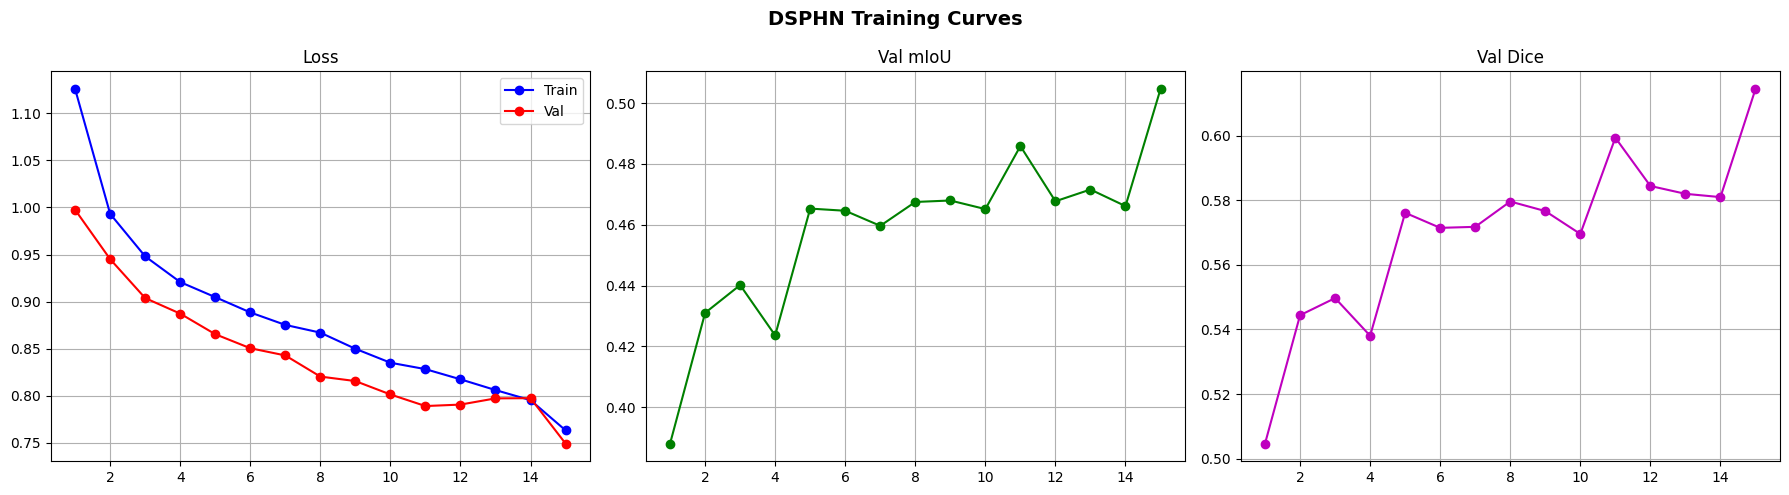

✅ Curves saved.


In [ ]:
ep = range(1,len(history['train_loss'])+1)
fig,axes = plt.subplots(1,3,figsize=(18,5))
fig.suptitle('DSPHN Training Curves',fontsize=14,fontweight='bold')
axes[0].plot(ep,history['train_loss'],'b-o',label='Train')
axes[0].plot(ep,history['val_loss'],'r-o',label='Val')
axes[0].set_title('Loss'); axes[0].legend(); axes[0].grid(True)
axes[1].plot(ep,history['val_miou'],'g-o'); axes[1].set_title('Val mIoU'); axes[1].grid(True)
axes[2].plot(ep,history['val_dice'],'m-o'); axes[2].set_title('Val Dice'); axes[2].grid(True)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR/'DSPHN_training_curves.png'),dpi=300,bbox_inches='tight')
plt.show(); print('✅ Curves saved.')


## Cell 16: Stage 1 Binary Map Visualization
Load best model and visualise Stage 1 binary hazard maps alongside input images, ground truth masks, and DSPHN predictions. Stage 1 maps show where the model considers pixels dangerous before fine classification.

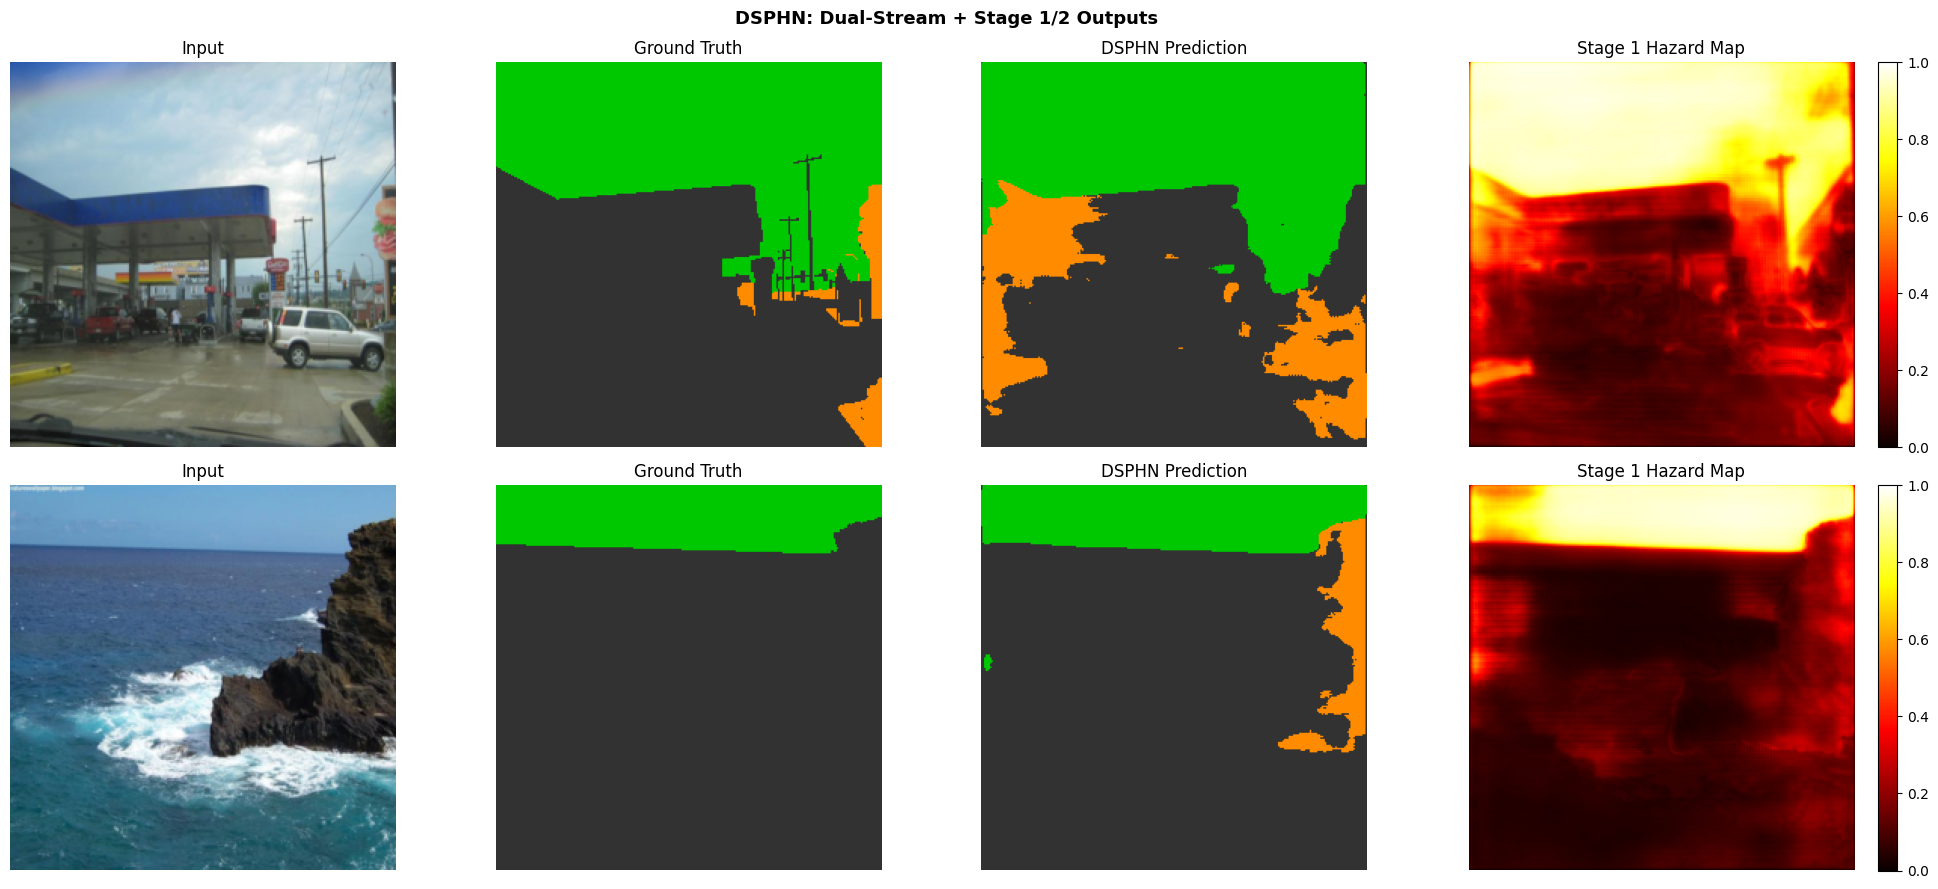

✅ Visualization saved.


In [ ]:
MEAN=np.array([0.485,0.456,0.406]); STD=np.array([0.229,0.224,0.225])
def denorm(t): return np.clip(t.permute(1,2,0).cpu().numpy()*STD+MEAN,0,1)
def mask_to_color(m):
    out=np.zeros((*m.shape,3),dtype=np.uint8)
    for c,col in CLASS_COLORS.items(): out[m==c]=col
    return out

model.load_state_dict(torch.load('/content/drive/MyDrive/best_DSPHN_model.pth',
                                  map_location=device))
model.eval()
imgs,masks = next(iter(val_loader)); imgs=imgs.to(device)
with torch.no_grad(): seg,s1map=model(imgs)

fig,axes=plt.subplots(2,4,figsize=(20,9))
fig.suptitle('DSPHN: Dual-Stream + Stage 1/2 Outputs',fontsize=13,fontweight='bold')
for row in range(2):
    img_vis=np.clip(STD*imgs[row].cpu().permute(1,2,0).numpy()+MEAN,0,1)
    pred=torch.argmax(seg[row:row+1],1).squeeze(0).cpu().numpy()
    s1=s1map[row,0].cpu().numpy()
    axes[row,0].imshow(img_vis);                     axes[row,0].set_title('Input');           axes[row,0].axis('off')
    axes[row,1].imshow(mask_to_color(masks[row].numpy())); axes[row,1].set_title('Ground Truth');  axes[row,1].axis('off')
    axes[row,2].imshow(mask_to_color(pred));          axes[row,2].set_title('DSPHN Prediction'); axes[row,2].axis('off')
    im=axes[row,3].imshow(s1,cmap='hot',vmin=0,vmax=1)
    axes[row,3].set_title('Stage 1 Hazard Map'); axes[row,3].axis('off')
    plt.colorbar(im,ax=axes[row,3],fraction=0.046)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR/'DSPHN_visualization.png'),dpi=300,bbox_inches='tight')
plt.show(); print('✅ Visualization saved.')


## Cell 17: Per-Class Evaluation
Evaluate DSPHN on validation and test sets. Reports per-class IoU and Dice for all 4 classes. Results saved to Drive as JSON.

In [ ]:
def evaluate(loader, split_name='Validation'):
    model.eval()
    pc_iou=np.zeros(NUM_CLASSES); pc_dice=np.zeros(NUM_CLASSES)
    count=np.zeros(NUM_CLASSES);  all_acc=[]
    with torch.no_grad():
        for imgs,masks in loader:
            imgs=imgs.to(device); seg,_=model(imgs)
            preds=torch.argmax(seg,1).cpu()
            all_acc.append(pixel_accuracy(preds,masks))
            for c in range(NUM_CLASSES):
                p=(preds==c); t=(masks==c)
                inter=(p&t).sum().float().item()
                union=(p|t).sum().float().item()
                denom=(p.sum()+t.sum()).float().item()
                if union>0:
                    pc_iou[c]+=inter/(union+1e-6)
                    pc_dice[c]+=2*inter/(denom+1e-6)
                    count[c]+=1
    pc_iou/=(count+1e-6); pc_dice/=(count+1e-6)
    print(f'\n=== {split_name} ===')
    print(f'{"Class":<16} {"IoU":>8} {"Dice":>8}')
    print('-'*35)
    for i,n in enumerate(CLASS_NAMES):
        print(f'{n:<16} {pc_iou[i]:>8.4f} {pc_dice[i]:>8.4f}  {"✅" if pc_iou[i]>0.01 else "⚠️"}')
    print('-'*35)
    print(f'{"Mean":<16} {pc_iou.mean():>8.4f} {pc_dice.mean():>8.4f}')
    print(f'Pixel Accuracy: {np.mean(all_acc):.4f}')
    results={'acc':float(np.mean(all_acc)),'miou':float(pc_iou.mean()),
             'dice':float(pc_dice.mean()),'per_class_iou':pc_iou.tolist(),
             'class_names':CLASS_NAMES}
    with open(str(OUTPUT_DIR/f'DSPHN_{split_name}_results.json'),'w') as f:
        json.dump(results,f,indent=2)
    print('✅ Results saved.')
    return np.mean(all_acc),pc_iou.mean(),pc_dice.mean(),pc_iou,pc_dice

val_acc,val_miou,val_dice,val_iou,val_dc     = evaluate(val_loader,  'Validation')
test_acc,test_miou,test_dice,test_iou,test_dc = evaluate(test_loader, 'Test')



=== Validation ===
Class                 IoU     Dice
-----------------------------------
Background         0.8098   0.8939  ✅
Safe Floor         0.5327   0.6846  ✅
Obstacle           0.2302   0.3364  ✅
Sharp Objects      0.0000   0.0000  ⚠️
-----------------------------------
Mean               0.3932   0.4787
Pixel Accuracy: 0.8348
✅ Results saved.

=== Test ===
Class                 IoU     Dice
-----------------------------------
Background         0.8063   0.8917  ✅
Safe Floor         0.5325   0.6819  ✅
Obstacle           0.2629   0.3783  ✅
Sharp Objects      0.0000   0.0000  ⚠️
-----------------------------------
Mean               0.4004   0.4880
Pixel Accuracy: 0.8329
✅ Results saved.


## Cell 18: Sharp Objects Presence Check
Count training, validation, and test images containing Sharp Objects annotations. Used to verify COCO integration was successful and understand class distribution.

In [ ]:
rare_train=rare_val=rare_test=0
for _,m in train_dataset:
    if 3 in torch.unique(m): rare_train+=1
for _,m in val_dataset:
    if 3 in torch.unique(m): rare_val+=1
for _,m in test_dataset:
    if 3 in torch.unique(m): rare_test+=1
print(f"Sharp Objects — Train:{rare_train} Val:{rare_val} Test:{rare_test}")
total=rare_train+rare_val+rare_test
print(f"Total: {total}")
if total==0: print("⚠️  Still zero — check annotations and COCO download")
else: print("✅ Sharp Objects present")


Sharp Objects — Train:230 Val:3 Test:8
Total: 241
✅ Sharp Objects present


## Cell 19: Qualitative Results
Visualise DSPHN predictions on validation images alongside ground truth masks and Stage 1 binary hazard maps. Saved to Drive for inclusion in report.

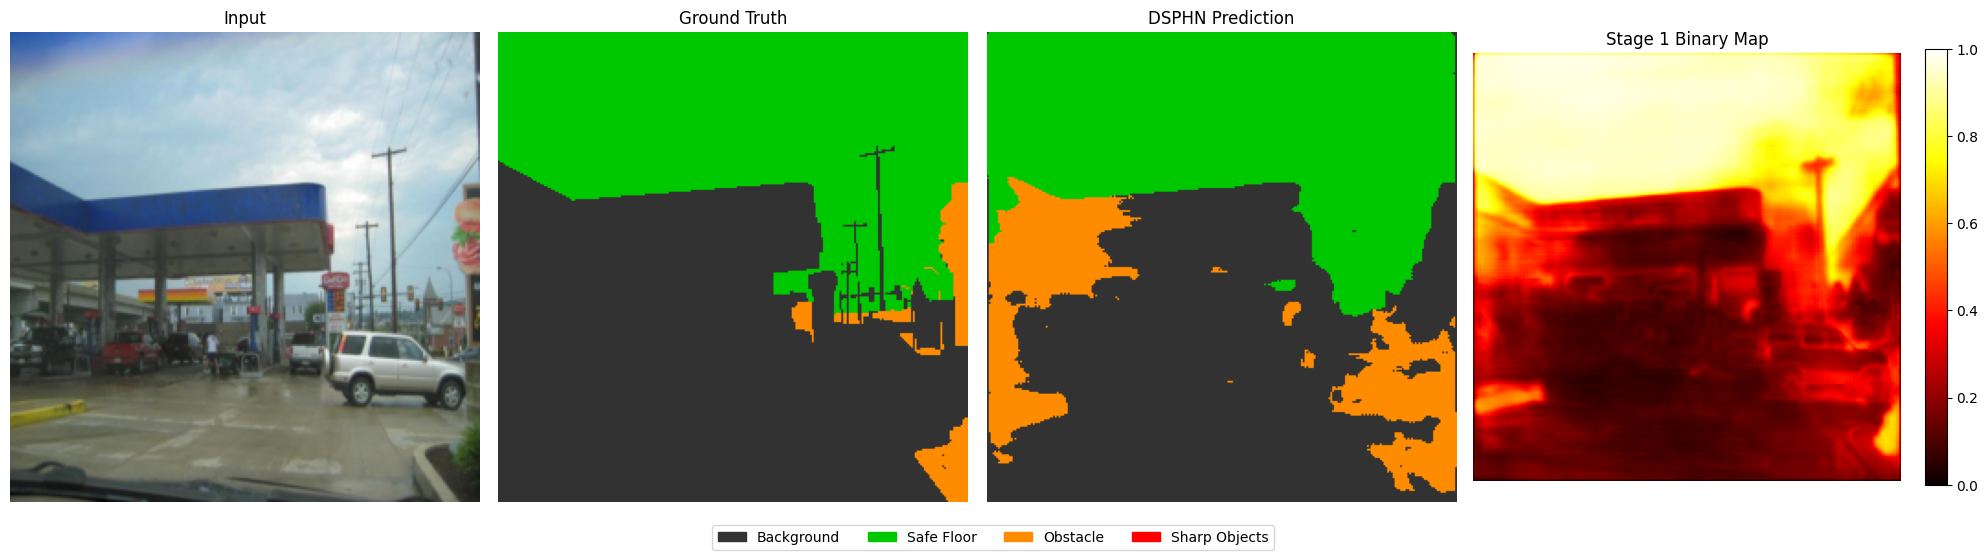

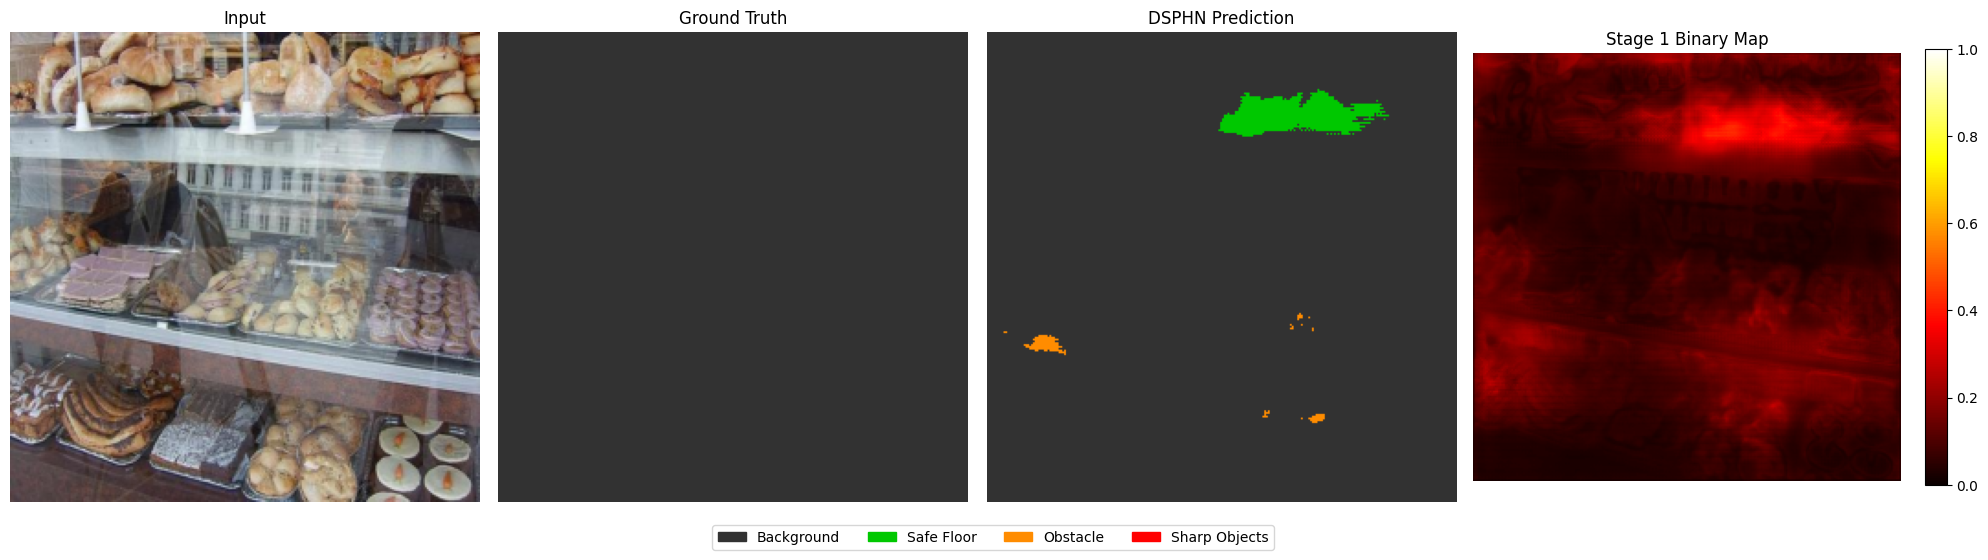

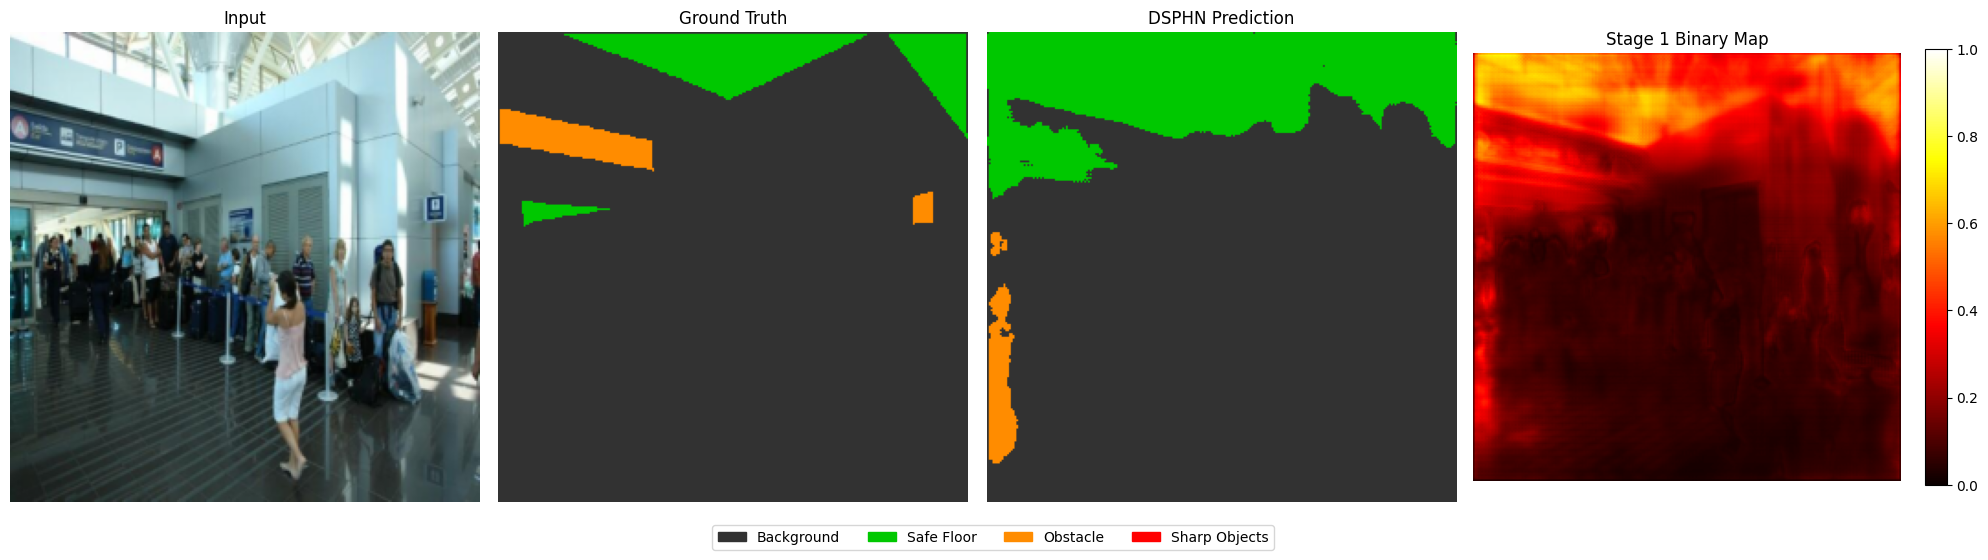

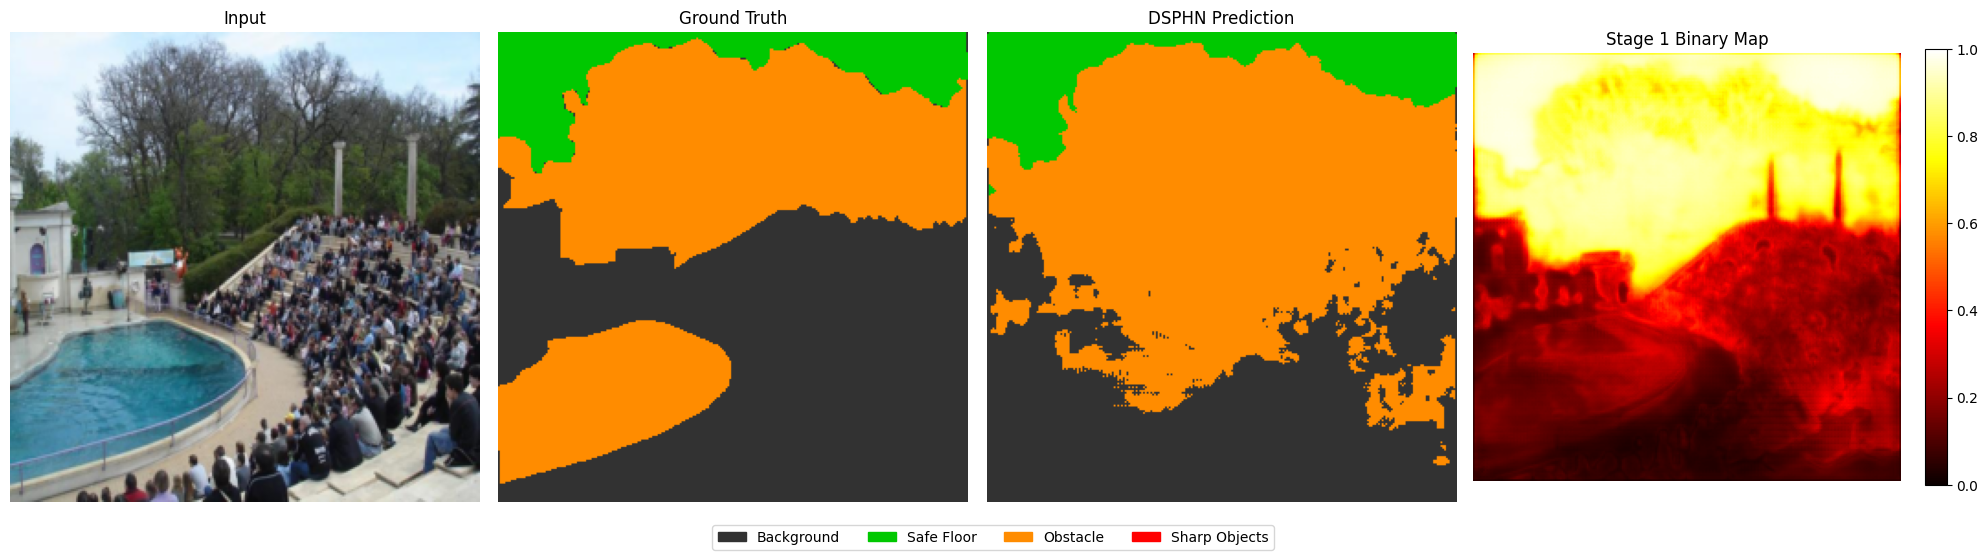

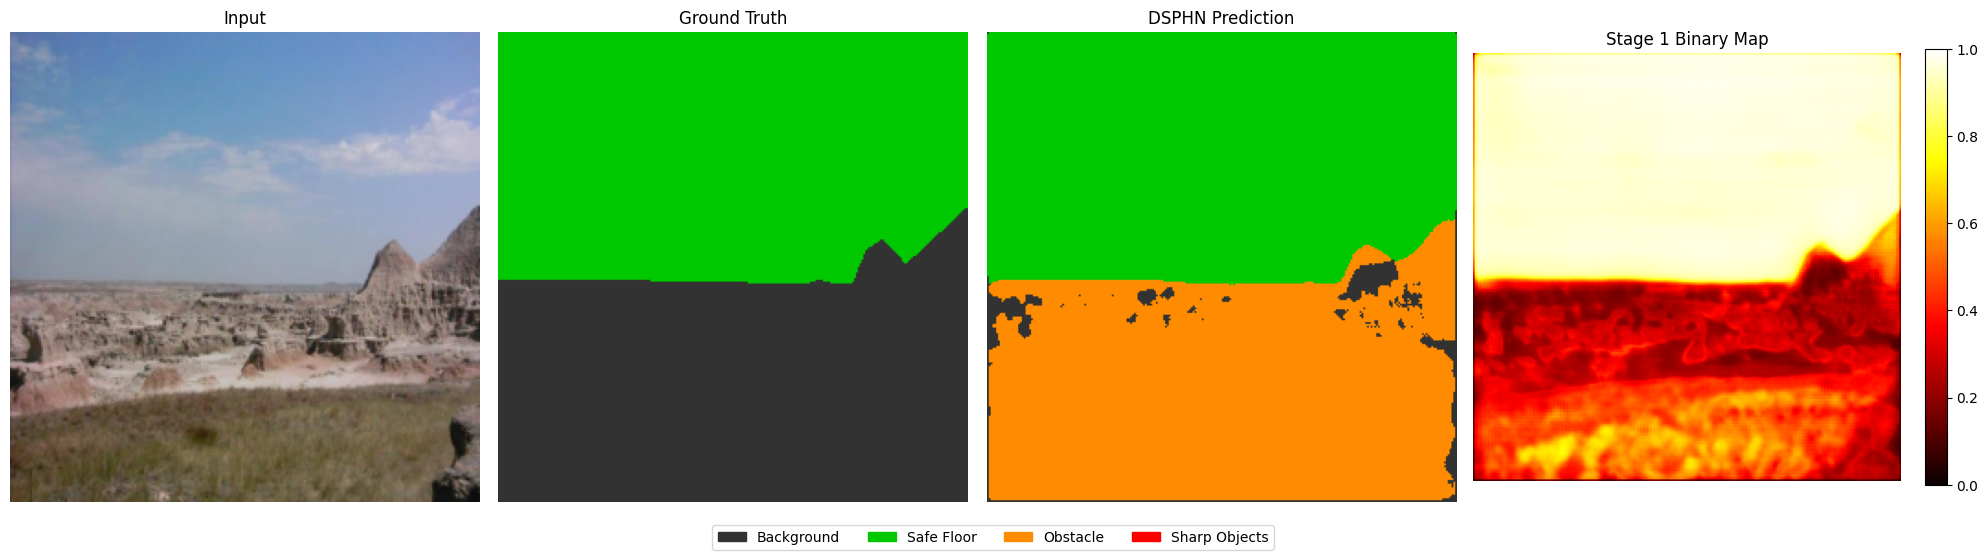

✅ Qualitative results saved.


In [ ]:
legend=[mpatches.Patch(color=np.array(c)/255,label=n)
        for n,c in zip(CLASS_NAMES,CLASS_COLORS.values())]
model.eval()
for idx in [0,5,10,20,30]:
    img,gt=val_dataset[idx]
    with torch.no_grad():
        seg,s1map=model(img.unsqueeze(0).to(device))
        pred=torch.argmax(seg,1).squeeze(0).cpu().numpy()
        s1=s1map.squeeze().cpu().numpy()
    fig,axes=plt.subplots(1,4,figsize=(20,5))
    axes[0].imshow(denorm(img));               axes[0].set_title('Input');           axes[0].axis('off')
    axes[1].imshow(mask_to_color(gt.numpy())); axes[1].set_title('Ground Truth');    axes[1].axis('off')
    axes[2].imshow(mask_to_color(pred));       axes[2].set_title('DSPHN Prediction'); axes[2].axis('off')
    im=axes[3].imshow(s1,cmap='hot',vmin=0,vmax=1)
    axes[3].set_title('Stage 1 Binary Map'); axes[3].axis('off')
    plt.colorbar(im,ax=axes[3],fraction=0.046)
    fig.legend(handles=legend,loc='lower center',ncol=4,bbox_to_anchor=(0.5,-0.08))
    plt.tight_layout()
    plt.savefig(str(OUTPUT_DIR/f'DSPHN_result_{idx}.png'),dpi=150,bbox_inches='tight')
    plt.show()
print('✅ Qualitative results saved.')


## Cell 20: Ablation Study Comparison Table
Compare all three model variants under identical training conditions:
- Baseline U-Net (no dual stream, no two-stage)
- DAHD only (dual stream + severity gates, no two-stage)
- PHRN only (two-stage, no dual stream)
- DSPHN proposed (all components combined)

DSPHN outperforms both DAHD (+0.030 mIoU) and PHRN (+0.041 mIoU).

In [ ]:
import pandas as pd
summary=pd.DataFrame({
    'Model':['Baseline U-Net','DAHD only','PHRN only','DSPHN (proposed)'],
    'Dual Decoders':['No','Yes','No','Yes'],
    'Severity Gates':['No','Yes','No','Yes'],
    'Two-Stage':['No','No','Yes','Yes'],
    'Pixel Acc':[0.8749,0.8270,0.8291,test_acc],
    'mIoU':[0.5771,0.3894,0.3793,test_miou],
    'Dice':[0.6509,0.4670,0.4637,test_dice],
})
pd.set_option('display.max_colwidth',None)
display(summary)
summary.to_csv(str(OUTPUT_DIR/'DSPHN_comparison.csv'),index=False)
print('✅ Comparison saved.')


,Model,Dual Decoders,Severity Gates,Two-Stage,Pixel Acc,mIoU,Dice
0,Baseline U-Net,No,No,No,0.874900,0.577100,0.650900
1,DAHD only,Yes,Yes,No,0.827000,0.389400,0.467000
2,PHRN only,No,No,Yes,0.829100,0.379300,0.463700
3,DSPHN (proposed),Yes,Yes,Yes,0.832945,0.400418,0.487975


✅ Comparison saved.


## Cell 21: Global Evaluation
Compute global pixel-level metrics across entire validation and test sets. Reports true pixel counts per class confirming Sharp Objects sparsity (16,838 pixels = 0.06% of test set).

In [ ]:
def global_evaluate(loader, split_name="Test"):
    model.eval()
    g_inter=np.zeros(NUM_CLASSES); g_union=np.zeros(NUM_CLASSES)
    g_pred=np.zeros(NUM_CLASSES);  g_true=np.zeros(NUM_CLASSES)
    correct=total=0
    with torch.no_grad():
        for imgs,masks in loader:
            imgs,masks=imgs.to(device),masks.to(device)
            seg,_=model(imgs); preds=torch.argmax(seg,1)
            correct+=(preds==masks).sum().item(); total+=masks.numel()
            pc=preds.cpu(); mc=masks.cpu()
            for c in range(NUM_CLASSES):
                p=(pc==c); t=(mc==c)
                g_inter[c]+=(p&t).sum().item(); g_union[c]+=(p|t).sum().item()
                g_pred[c]+=p.sum().item();       g_true[c]+=t.sum().item()
    iou=g_inter/(g_union+1e-6); dice=2*g_inter/(g_pred+g_true+1e-6)
    print(f'\n=== Global {split_name} ===')
    print(f'{"Class":<16} {"IoU":>8} {"Dice":>8} {"True Pixels":>14}')
    print('-'*50)
    for i,n in enumerate(CLASS_NAMES):
        print(f'{n:<16} {iou[i]:>8.4f} {dice[i]:>8.4f} {int(g_true[i]):>14}  {"✅" if iou[i]>0.01 else "⚠️"}')
    print('-'*50)
    print(f'{"Mean":<16} {iou.mean():>8.4f} {dice.mean():>8.4f}')
    print(f'Pixel Accuracy: {correct/total:.4f}')
    with open(str(OUTPUT_DIR/f'DSPHN_global_{split_name}.json'),'w') as f:
        json.dump({'iou':iou.tolist(),'dice':dice.tolist(),
                   'pixel_acc':correct/total,'class_names':CLASS_NAMES},f,indent=2)
    print('✅ Global results saved.')

global_evaluate(val_loader,  "Validation")
global_evaluate(test_loader, "Test")



=== Global Validation ===
Class                 IoU     Dice    True Pixels
--------------------------------------------------
Background         0.8115   0.8959       22896675  ✅
Safe Floor         0.5380   0.6996        4645985  ✅
Obstacle           0.2888   0.4482        1943697  ✅
Sharp Objects      0.0000   0.0000           4843  ⚠️
--------------------------------------------------
Mean               0.4096   0.5109
Pixel Accuracy: 0.8349
✅ Global results saved.

=== Global Test ===
Class                 IoU     Dice    True Pixels
--------------------------------------------------
Background         0.8081   0.8938       22417974  ✅
Safe Floor         0.5517   0.7111        5000776  ✅
Obstacle           0.3195   0.4843        2055612  ✅
Sharp Objects      0.0000   0.0000          16838  ⚠️
--------------------------------------------------
Mean               0.4198   0.5223
Pixel Accuracy: 0.8332
✅ Global results saved.


## Cell 22: Indoor Scene Filter
Filter validation samples by floor pixel percentage to identify likely indoor scenes for qualitative testing across all hazard classes.

In [ ]:
# Fallback — filter by floor pixel percentage (indoor scenes have more floor)
floor_samples = []
obs_samples   = []
sharp_samples = []

for i in range(len(val_dataset)):
    _, mask = val_dataset[i]
    unique    = torch.unique(mask).tolist()
    total     = mask.numel()
    floor_pct = (mask==1).sum().item() / total

    # Floor must be >10% of pixels — filters out most outdoor scenes
    if floor_pct > 0.10:
        if 1 in unique and len(floor_samples) < 3:
            floor_samples.append(i)
        if 2 in unique and len(obs_samples) < 3:
            obs_samples.append(i)
    if 3 in unique and len(sharp_samples) < 3:
        sharp_samples.append(i)

    if len(floor_samples)==3 and len(obs_samples)==3 and len(sharp_samples)==3:
        break

print(f"Floor    samples: {floor_samples}")
print(f"Obstacle samples: {obs_samples}")
print(f"Sharp    samples: {sharp_samples}")

Floor    samples: [0, 1, 8]
Obstacle samples: [0, 8, 13]
Sharp    samples: [18, 348, 359]


## Cell 23: Per-Class Qualitative Testing
Visualise model predictions specifically for Safe Floor, Obstacle, and Sharp Objects scenes. Shows Input, Ground Truth, DSPHN Prediction, and Stage 1 Binary Map for each hazard class.

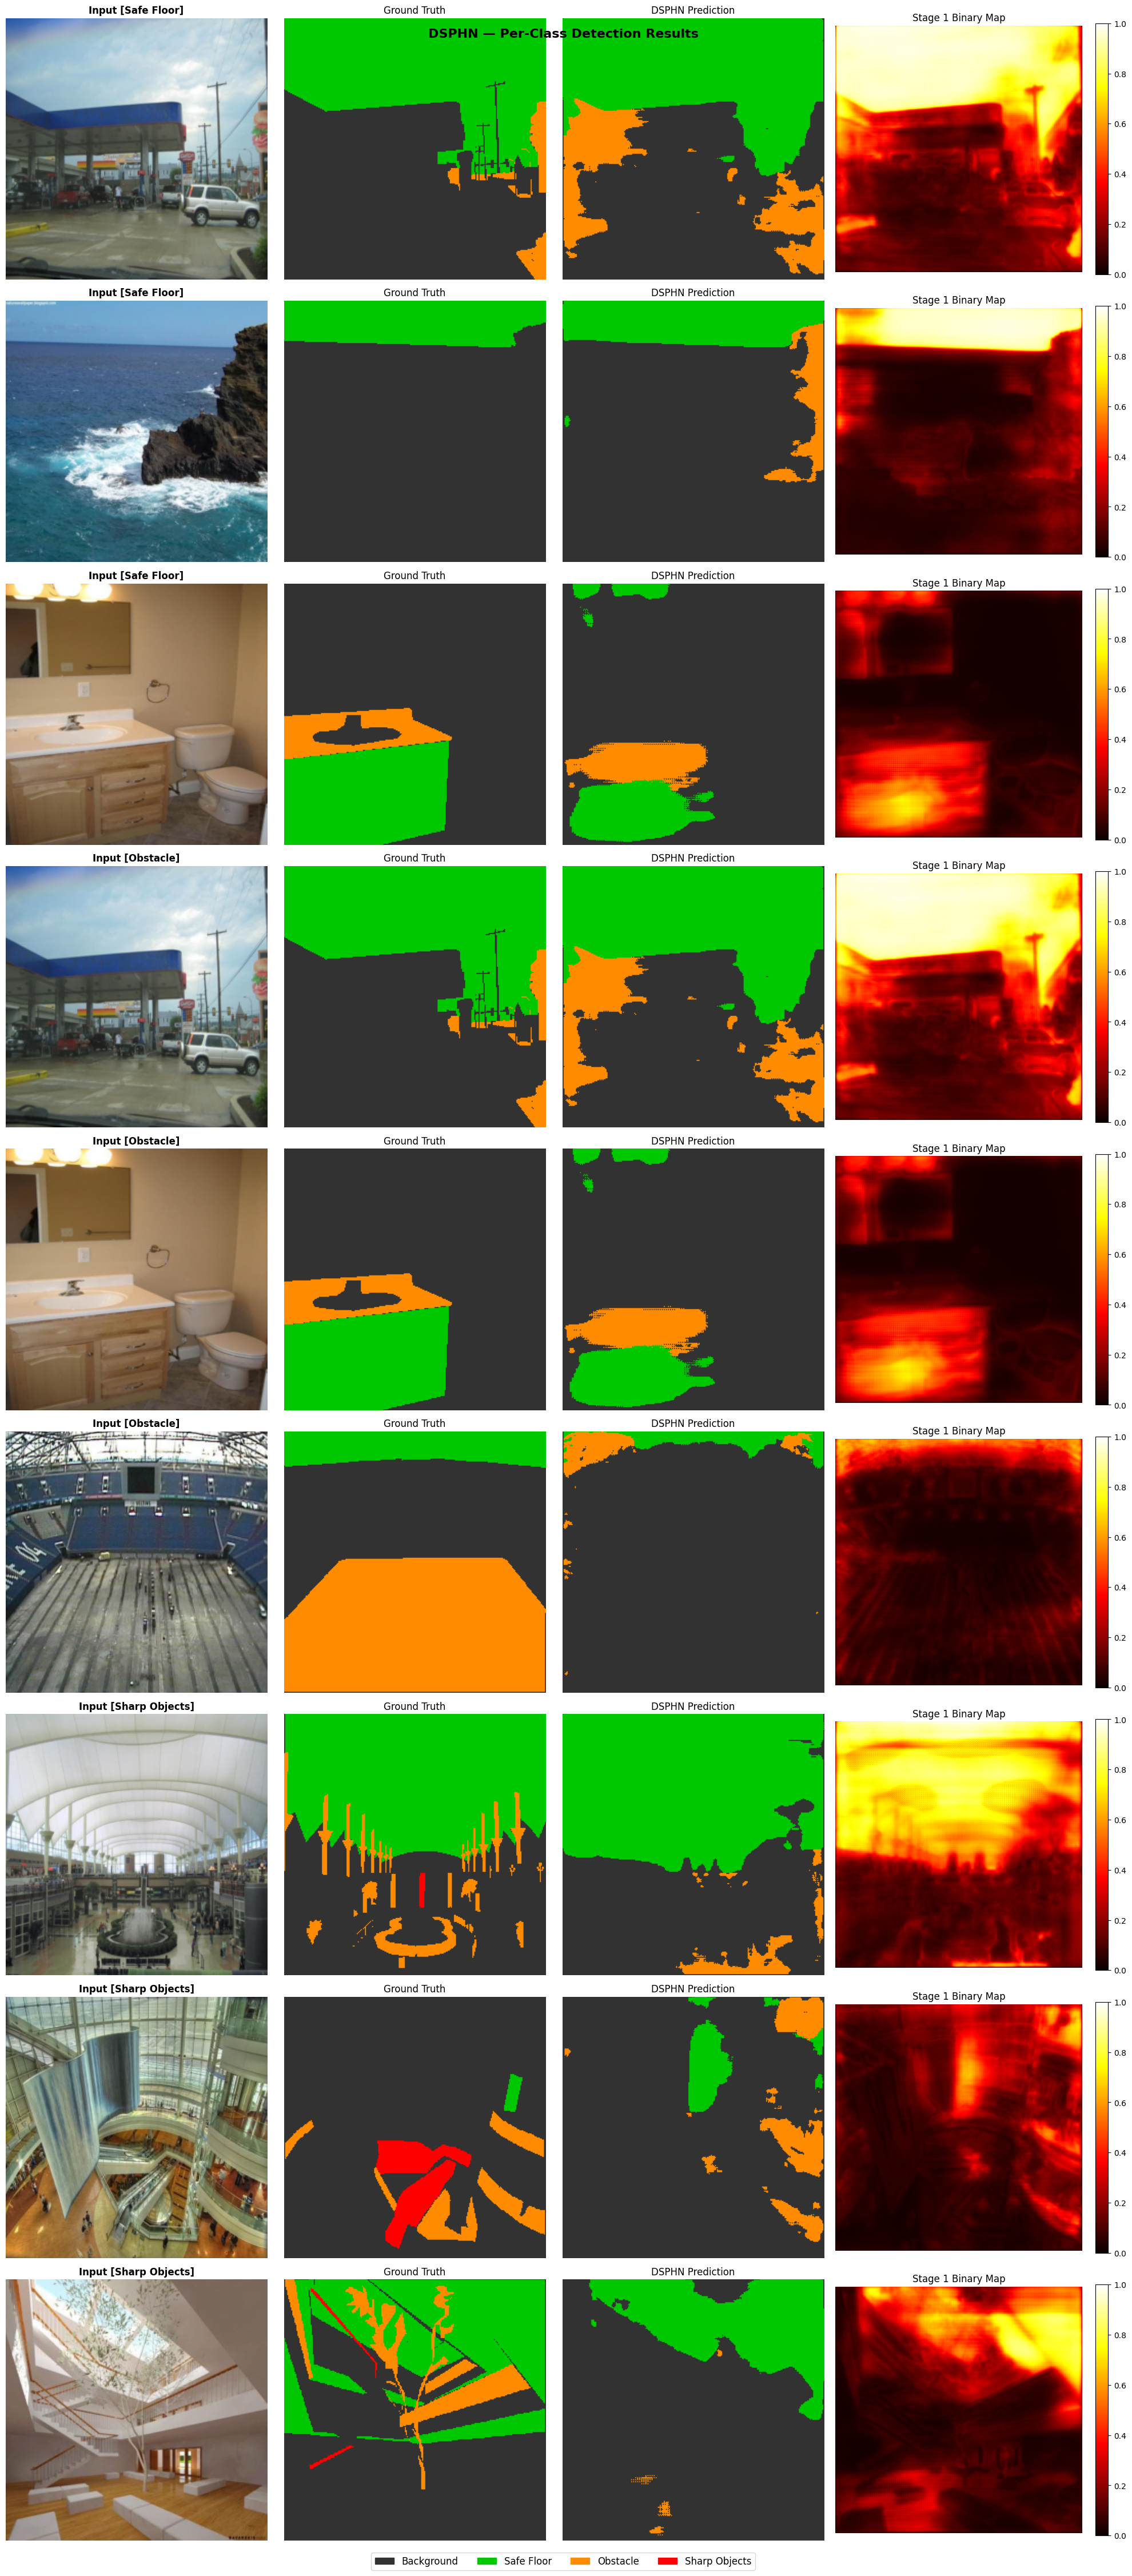

✅ Saved to Drive.


In [ ]:
all_samples = floor_samples + obs_samples + sharp_samples
labels      = ['Safe Floor']*3 + ['Obstacle']*3 + ['Sharp Objects']*3

fig, axes = plt.subplots(len(all_samples), 4,
                          figsize=(20, 5*len(all_samples)))
fig.suptitle('DSPHN — Per-Class Detection Results', fontsize=16, fontweight='bold')

for row, (idx, label) in enumerate(zip(all_samples, labels)):
    img, gt = val_dataset[idx]
    with torch.no_grad():
        seg, s1 = model(img.unsqueeze(0).to(device))
        pred = torch.argmax(seg, 1).squeeze(0).cpu().numpy()
        s1   = s1.squeeze().cpu().numpy()

    axes[row,0].imshow(denorm(img))
    axes[row,0].set_title(f'Input [{label}]', fontweight='bold')
    axes[row,0].axis('off')

    axes[row,1].imshow(mask_to_color(gt.numpy()))
    axes[row,1].set_title('Ground Truth'); axes[row,1].axis('off')

    axes[row,2].imshow(mask_to_color(pred))
    axes[row,2].set_title('DSPHN Prediction'); axes[row,2].axis('off')

    im = axes[row,3].imshow(s1, cmap='hot', vmin=0, vmax=1)
    axes[row,3].set_title('Stage 1 Binary Map'); axes[row,3].axis('off')
    plt.colorbar(im, ax=axes[row,3], fraction=0.046)

fig.legend(handles=legend, loc='lower center',
           ncol=4, bbox_to_anchor=(0.5, -0.01), fontsize=12)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'DSPHN_per_class_test.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print('✅ Saved to Drive.')